In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
def create_alpha(size, base_val, target_val, start, end):
    alpha = np.full(size, base_val)
    alpha[start:end] = target_val
    return alpha



In [17]:

import pymc as pm
from pymc.pytensorf import collect_default_updates
import numpy as np
import pytensor
import pytensor.tensor as pt

from scipy.linalg import toeplitz

## https://www.pymc.io/projects/examples/en/latest/time_series/Time_Series_Generative_Graph.html

PITCH_ALPHABET = list("abcdefghjklmnopqrs")
V = len(PITCH_ALPHABET)

MAX_SEQ_LEN = 30


def step_fn(x_prev, A):
    p_next = A[x_prev]
    x_tp1 = pm.Categorical.dist(p_next)
    return x_tp1, collect_default_updates([x_tp1])


def scan_dist(x_0, A, length, size):
    sequence, _ = pytensor.scan(
        fn=step_fn,
        outputs_info={"initial": x_0},
        non_sequences=[A],
        n_steps=length-1,
        strict=True,
    )
    return sequence


coords = {
    "steps": range(MAX_SEQ_LEN - 1),
    "full_sequence": range(MAX_SEQ_LEN),
}


with pm.Model(coords=coords) as model:
    length = pm.Poisson("length", MAX_SEQ_LEN)
    alpha = np.ones(V) 
   
    
    beta = np.ones((V,V))
    
    pi = pm.Dirichlet("pi", a=alpha)
    A = pm.Dirichlet("A", a=beta) # shape=(V, V)
    x_0 = pm.Categorical("x_0", p=pi)
    
    steps = pm.CustomDist(
        "x_t+1",
        x_0,
        A,
        length,
        dist=scan_dist,
       #dims=("steps",),
    )

 

AttributeError: 'numpy.ndarray' object has no attribute 'type'

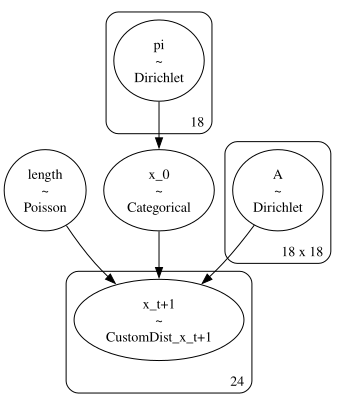

In [6]:
pm.model_to_graphviz(model)

In [8]:

with model:
    prior_samples = pm.sample_prior_predictive(samples=1)

import model_utils 
import pandas as pd
pitch_0 = prior_samples.prior["x_0"].to_series()
pitch_series = prior_samples.prior["x_t+1"].to_series()

sequence = pd.concat([pitch_0, pitch_series])

melody = model_utils.to_pitches(sequence, PITCH_ALPHABET)
model_utils.to_volpiano(melody)

Sampling: [A, length, pi, x_0, x_t+1]


In [16]:
prior_samples.prior

<xarray.Dataset> Size: 4kB
Dimensions:      (chain: 1, draw: 1, pi_dim_0: 18, x_t+1_dim_0: 26,
                  A_dim_0: 18, A_dim_1: 18)
Coordinates:
  * chain        (chain) int64 8B 0
  * draw         (draw) int64 8B 0
  * pi_dim_0     (pi_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * x_t+1_dim_0  (x_t+1_dim_0) int64 208B 0 1 2 3 4 5 6 ... 19 20 21 22 23 24 25
  * A_dim_0      (A_dim_0) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
  * A_dim_1      (A_dim_1) int64 144B 0 1 2 3 4 5 6 7 ... 11 12 13 14 15 16 17
Data variables:
    pi           (chain, draw, pi_dim_0) float64 144B 0.03785 ... 0.08153
    x_t+1        (chain, draw, x_t+1_dim_0) int64 208B 15 16 5 16 ... 16 14 12 8
    A            (chain, draw, A_dim_0, A_dim_1) float64 3kB 0.06909 ... 0.00...
    x_0          (chain, draw) int64 8B 14
    length       (chain, draw) int64 8B 27
Attributes:
    created_at:                 2026-03-16T12:05:23.632633+00:00
    arviz_version:              0.23.4
    inference_library:          pymc
    inference_library_version:  5.28.1

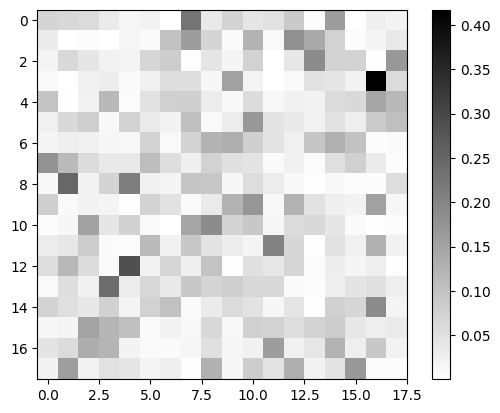

In [14]:
model_utils.plot_heatmap(prior_samples.prior.A.sel(chain=0, draw=0))